# Phase 2 · Exploratory analysis

Before answering the project's business questions, we need to understand how sales behave. In this notebook we look at:

- how sales evolve month by month, and whether there are high and low seasons;
- which days of the week and which hours concentrate the purchases;
- how much a customer spends per order (average ticket) and how many products they buy;
- how sales are split across categories and regions.

**Input:** the SQLite database `olist.db` created in Phase 1. The SQL queries are in the `sql/` folder.

**Output:** `monthly_sales.csv` in `data/processed/`, with each month's indicators for the dashboard.

All amounts are in Brazilian reais (R$), and revenue excludes freight unless stated otherwise.

## 1. Libraries, paths, chart style and SQL helper

We define the colors and chart style once, so every chart in the notebook looks consistent. Blue is used for the main data and grays for context.

From this phase on, aggregations are written in SQL and kept in the `sql/` folder, one file per query. The `run_sql` function reads a file, prints the query so it can be read in the notebook, and returns the result as a table. Python takes over for statistics and charts.

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Patch

PROCESSED = Path("..") / "data" / "processed"
DATABASE = PROCESSED / "olist.db"
SQL_DIR = Path("..") / "sql"
FIGURES = Path("..") / "reports" / "figures"
pd.set_option("display.max_columns", 40)

BLUE = "#2a78d6"
GRAY = "#898781"
LIGHT_GRAY = "#c3c2b7"
INK = "#0b0b0b"
SECONDARY_INK = "#52514e"
GRID = "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.edgecolor": LIGHT_GRAY,
    "axes.labelcolor": SECONDARY_INK,
    "axes.titlecolor": INK,
    "axes.titlelocation": "left",
    "axes.titlesize": 12,
    "axes.titlepad": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": SECONDARY_INK,
    "ytick.color": SECONDARY_INK,
    "xtick.major.size": 0,
    "ytick.major.size": 0,
    "legend.frameon": False,
})

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]


def run_sql(name, show=True, **params):
    # Reads sql/<name>.sql, prints it and returns the result as a DataFrame
    query = (SQL_DIR / f"{name}.sql").read_text(encoding="utf-8")
    if show:
        print(query)
    with closing(sqlite3.connect(DATABASE)) as connection:
        return pd.read_sql_query(query, connection, params=params)


def run_sql_script(name):
    # Runs a file with several statements, such as the creation of a view
    script = (SQL_DIR / f"{name}.sql").read_text(encoding="utf-8")
    print(script)
    with closing(sqlite3.connect(DATABASE)) as connection:
        connection.executescript(script)

## 2. Analysis period

We work with the 20 months from January 2017 to August 2018. Phase 1 revealed two problems at the edges: 2016 has only 267 orders, and from August 22, 2018 the data stops being complete. So we leave 2016 out and, for daily averages and comparisons between periods, we only use days up to August 21, 2018.

The dates reach the queries as parameters (`:start` and `:end`, where `end` is excluded), so every query uses exactly the same period.

In [2]:
PERIOD = {"start": "2017-01-01", "end": "2018-09-01"}
# First day with incomplete data (see Phase 1, section 13)
CUTOFF = pd.Timestamp("2018-08-22")
COMPLETE_PERIOD = {"start": "2017-01-01", "end": "2018-08-22"}

## 3. Sales by month

For each month we compute orders, units, revenue, average ticket (revenue divided by orders) and distinct customers.

In [3]:
monthly = run_sql("monthly_sales", **PERIOD).set_index("month")
monthly.index = pd.PeriodIndex(monthly.index, freq="M")

-- Monthly sales indicators: orders, units, revenue, average ticket and distinct customers
SELECT
    strftime('%Y-%m-01', purchase_date) AS month,
    COUNT(*) AS orders,
    SUM(units) AS units,
    SUM(revenue) AS revenue,
    AVG(revenue) AS avg_ticket,
    COUNT(DISTINCT customer_unique_id) AS customers
FROM orders
WHERE purchase_date >= :start
  AND purchase_date < :end
GROUP BY month
ORDER BY month;



We also add **orders per day**, computed only with days that have complete data. This column corrects two things: months have different numbers of days (without it, February would look worse than it really was), and the August 2018 cutoff makes that month look weaker than it was. To compute it we first count the orders of each day with SQL, and then fill in with zeros the days without orders.

In [4]:
daily_sales = run_sql("daily_sales", **PERIOD)
daily = (
    daily_sales.assign(day=pd.to_datetime(daily_sales["day"]))
    .set_index("day")
    .reindex(pd.date_range("2017-01-01", "2018-08-31", freq="D"), fill_value=0)
)
daily_complete = daily[daily.index < CUTOFF]

monthly["orders_per_day"] = daily_complete.groupby(daily_complete.index.to_period("M"))["orders"].mean()
monthly["is_complete_month"] = monthly.index != pd.Period("2018-08", freq="M")
monthly.round({"revenue": 1, "avg_ticket": 1, "orders_per_day": 1})

-- Orders and revenue per purchase day
SELECT
    date(purchase_date) AS day,
    COUNT(*) AS orders,
    SUM(revenue) AS revenue
FROM orders
WHERE purchase_date >= :start
  AND purchase_date < :end
GROUP BY day
ORDER BY day;



,orders,units,revenue,avg_ticket,customers,orders_per_day,is_complete_month
month,,,,,,,
2017-01,750,913,111798.4,149.1,718,24.2,True
2017-02,1653,1858,234223.4,141.7,1630,59.0,True
2017-03,2546,2897,359198.8,141.1,2508,82.1,True
2017-04,2303,2569,340669.7,147.9,2274,76.8,True
2017-05,3545,4003,489159.2,138.0,3478,114.4,True
2017-06,3135,3489,421923.4,134.6,3076,104.5,True
2017-07,3872,4416,481604.5,124.4,3802,124.9,True
2017-08,4193,4797,554699.7,132.3,4114,135.3,True
2017-09,4150,4737,607399.7,146.4,4083,138.3,True


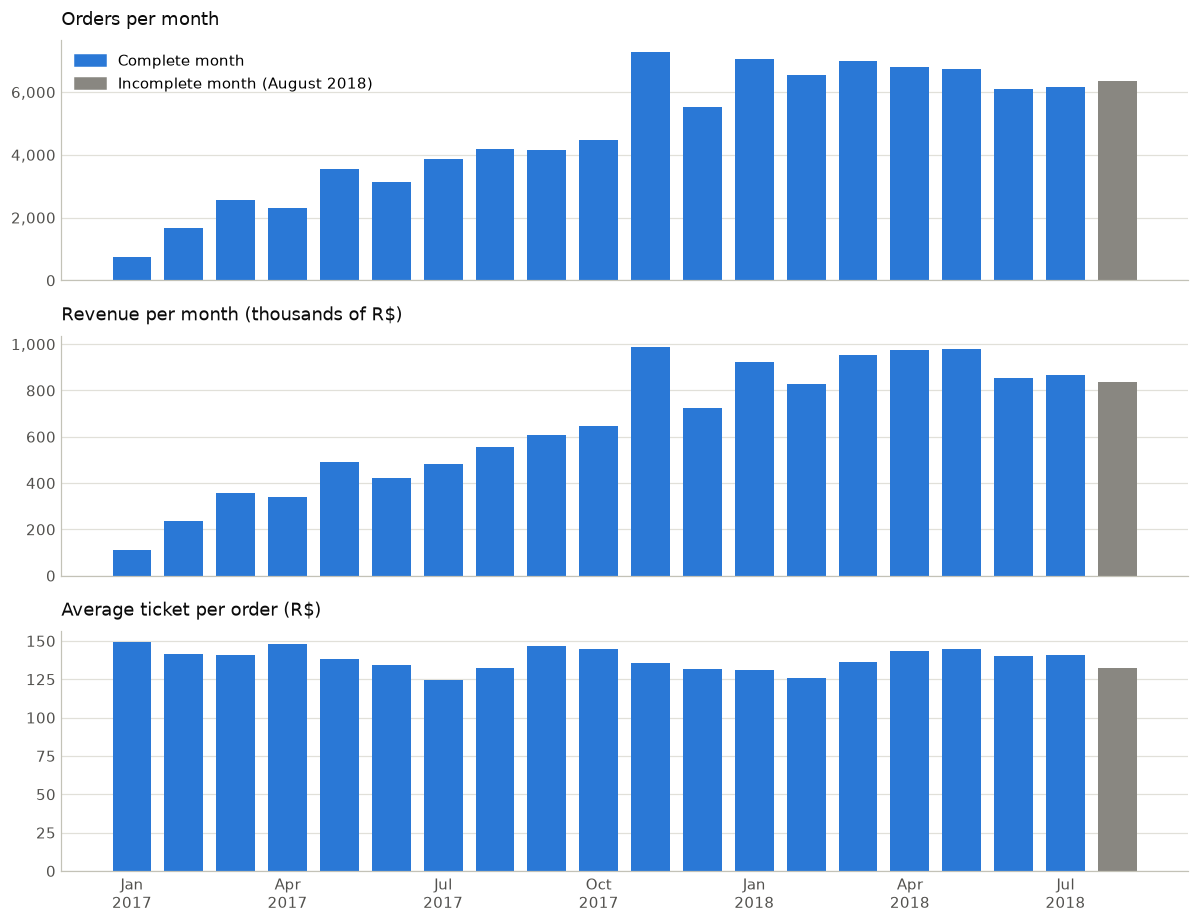

In [5]:
month_labels = [f"{MONTHS[p.month - 1]}\n{p.year}" if p.month in (1, 4, 7, 10) else "" for p in monthly.index]
x = np.arange(len(monthly))
colors = np.where(monthly["is_complete_month"], BLUE, GRAY)

panels = [
    ("Orders per month", monthly["orders"]),
    ("Revenue per month (thousands of R$)", monthly["revenue"] / 1000),
    ("Average ticket per order (R$)", monthly["avg_ticket"]),
]

fig, axes = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True)
for ax, (title, values) in zip(axes, panels):
    ax.bar(x, values.to_numpy(), color=colors, width=0.75)
    ax.set_title(title)
    ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
    ax.grid(axis="x", visible=False)
axes[0].legend(
    handles=[Patch(color=BLUE, label="Complete month"), Patch(color=GRAY, label="Incomplete month (August 2018)")],
    loc="upper left",
)
axes[-1].set_xticks(x, month_labels)
fig.tight_layout()
fig.savefig(FIGURES / "02_monthly_sales.png", dpi=150, bbox_inches="tight")
plt.show()

The chart shows two clearly different stages:

- During 2017, sales grew almost every month: from 750 orders in January to 4,478 in October.
- From January 2018 on, growth stopped and orders stabilized between 6,100 and 7,100 per month.

The average ticket, on the other hand, stayed almost flat, between R$ 124 and R$ 149 throughout the period. In other words, the business grew because more orders were placed, not because each order became more expensive. August 2018 is shown in gray because it is incomplete: counting only complete days, it ran at 270 orders per day, the highest rate of the whole period.

To measure growth we compare the same months of both years. We use January to July because August 2018 is incomplete.

In [6]:
def january_to_july(year):
    months = monthly[(monthly.index.year == year) & (monthly.index.month <= 7)]
    return months[["orders", "revenue"]].sum()


year_over_year = pd.DataFrame({
    "Jan-Jul 2017": january_to_july(2017),
    "Jan-Jul 2018": january_to_july(2018),
})
year_over_year["change_pct"] = (year_over_year["Jan-Jul 2018"] / year_over_year["Jan-Jul 2017"] - 1) * 100
year_over_year.round(1)

,Jan-Jul 2017,Jan-Jul 2018,change_pct
orders,17804.0,46426.0,160.8
revenue,2438577.4,6378595.6,161.6


Between January and July, orders grew 160.8% from 2017 to 2018 and revenue grew 161.6%. The two percentages being almost identical confirms what the chart shows: growth came from the number of orders, not from prices.

## 4. High and low seasons

The monthly chart hides what happens within each month. Here we plot the orders of each day (gray) together with their 30-day moving average (blue), which smooths the daily ups and downs and shows the trend. The moving average only uses complete days, so the August 2018 cutoff does not drag it down.

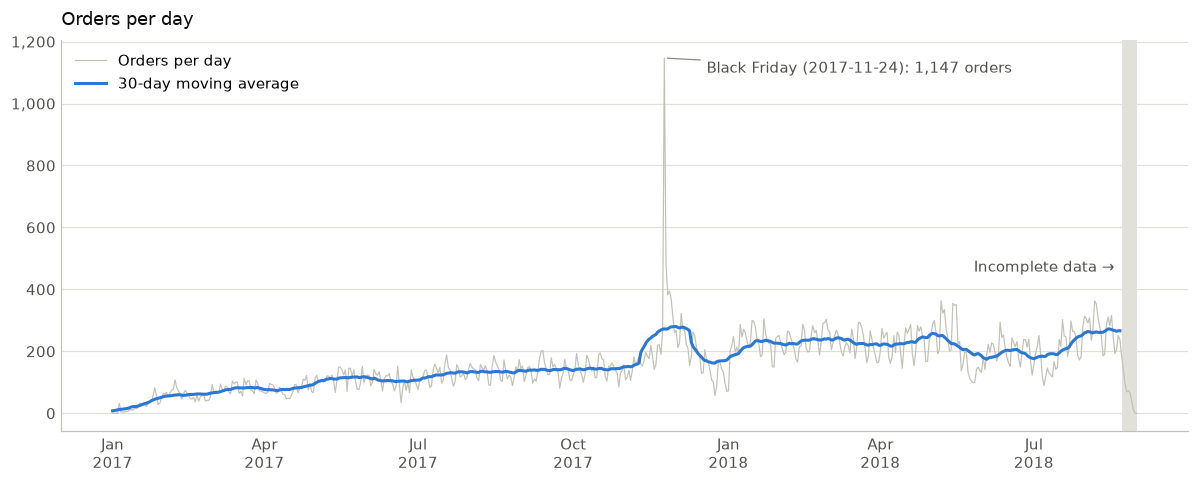

In [7]:
orders_per_day = daily["orders"]
moving_average = daily_complete["orders"].rolling(30, center=True, min_periods=15).mean()
peak_day = orders_per_day.idxmax()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.axvspan(CUTOFF, pd.Timestamp("2018-08-31"), color=GRID, linewidth=0)
ax.text(CUTOFF - pd.Timedelta(days=4), 470, "Incomplete data →", ha="right", va="center", color=SECONDARY_INK)
ax.plot(orders_per_day.index, orders_per_day.to_numpy(), color=LIGHT_GRAY, linewidth=0.8, label="Orders per day")
ax.plot(moving_average.index, moving_average.to_numpy(), color=BLUE, linewidth=2, label="30-day moving average")
ax.annotate(
    f"Black Friday ({peak_day:%Y-%m-%d}): {orders_per_day.max():,} orders",
    xy=(peak_day, orders_per_day.max()),
    xytext=(peak_day + pd.Timedelta(days=25), orders_per_day.max() * 0.97),
    ha="left", va="center", color=SECONDARY_INK,
    arrowprops={"arrowstyle": "-", "color": GRAY, "linewidth": 0.8},
)

quarters = pd.date_range("2017-01-01", "2018-08-31", freq="QS")
ax.set_xticks(quarters, [f"{MONTHS[d.month - 1]}\n{d.year}" for d in quarters])
ax.set_title("Orders per day")
ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "02_orders_per_day.png", dpi=150, bbox_inches="tight")
plt.show()

To compare stretches of different length, we use the average number of orders per day in each one.

In [8]:
stretches = {
    "October 2017": ("2017-10-01", "2017-10-31"),
    "November 2017": ("2017-11-01", "2017-11-30"),
    "December 2017": ("2017-12-01", "2017-12-31"),
    "January to May 2018": ("2018-01-01", "2018-05-31"),
    "June and July 2018": ("2018-06-01", "2018-07-31"),
    "August 1 to 21, 2018": ("2018-08-01", "2018-08-21"),
}
pd.Series(
    {name: daily_complete.loc[first:last, "orders"].mean() for name, (first, last) in stretches.items()},
    name="orders_per_day",
).round(1).to_frame()

,orders_per_day
October 2017,144.5
November 2017,242.9
December 2017,177.8
January to May 2018,226.3
June and July 2018,200.9
"August 1 to 21, 2018",270.0


With these figures we can identify the seasons:

- High season: November. Black Friday drives sales up: November 2017 had 243 orders per day, 68% more than October, and 1,147 orders were placed on November 24 alone.
- After the peak, December drops to 178 orders per day, 27% less than November, although it stays above October.
- 2018 shows a mid-year dip: from 226 orders per day between January and May to 201 in June and July (−11%). In the first three weeks of August the pace recovers strongly, to 270 orders per day.

A caveat that matters for the defense: with 20 months of data, each month from September to December appears only once. We cannot claim these patterns repeat every year. What the data does establish clearly is the Black Friday effect.

## 5. Day of the week and hour

To compare weekdays we use the **daily average** rather than the total: over 20 months, not every weekday appears the same number of times. We compute both orders and revenue to check whether they follow the same pattern. The hourly shares come straight from SQL, using a window function to divide each hour by the total.

In [9]:
by_weekday = (
    daily_complete.groupby(daily_complete.index.dayofweek)[["orders", "revenue"]].mean()
    .rename(columns={"orders": "avg_orders", "revenue": "avg_revenue"})
)
by_weekday.index = WEEKDAYS
by_weekday.round(1)

,avg_orders,avg_revenue
Monday,181.3,25115.8
Tuesday,179.2,24533.5
Wednesday,174.6,23802.3
Thursday,166.3,22769.0
Friday,159.4,22292.4
Saturday,122.9,17010.1
Sunday,134.2,17845.5


In [10]:
by_hour = run_sql("sales_by_hour", **COMPLETE_PERIOD).set_index("hour")

-- Share of orders and revenue by hour of purchase
WITH hourly AS (
    SELECT
        CAST(strftime('%H', purchase_date) AS INTEGER) AS hour,
        COUNT(*) AS orders,
        SUM(revenue) AS revenue
    FROM orders
    WHERE purchase_date >= :start
      AND purchase_date < :end
    GROUP BY hour
)
SELECT
    hour,
    orders,
    revenue,
    100.0 * orders / SUM(orders) OVER () AS orders_pct,
    100.0 * revenue / SUM(revenue) OVER () AS revenue_pct
FROM hourly
ORDER BY hour;



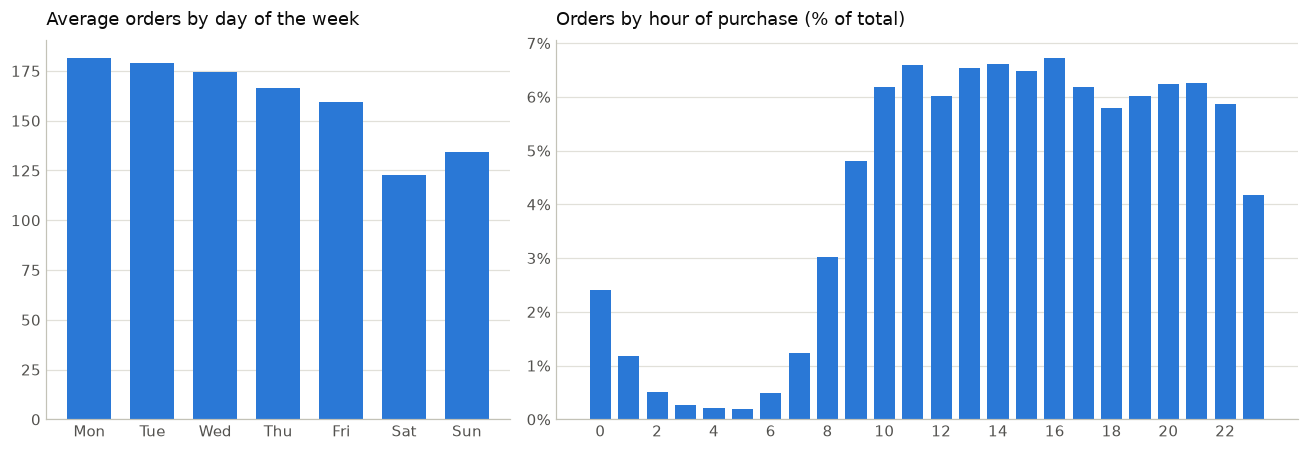

In [11]:
fig, (ax_day, ax_hour) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})

ax_day.bar([day[:3] for day in WEEKDAYS], by_weekday["avg_orders"].to_numpy(), color=BLUE, width=0.7)
ax_day.set_title("Average orders by day of the week")
ax_day.grid(axis="x", visible=False)

ax_hour.bar(by_hour.index, by_hour["orders_pct"].to_numpy(), color=BLUE, width=0.75)
ax_hour.set_title("Orders by hour of purchase (% of total)")
ax_hour.set_xticks(range(0, 24, 2))
ax_hour.yaxis.set_major_formatter(lambda value, _: f"{value:.0f}%")
ax_hour.grid(axis="x", visible=False)

fig.tight_layout()
fig.savefig(FIGURES / "02_weekday_hour.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
weekdays_avg = by_weekday.loc["Monday":"Friday", "avg_orders"].mean()
weekend_avg = by_weekday.loc[["Saturday", "Sunday"], "avg_orders"].mean()
print(f"Weekend compared with weekdays: {weekend_avg / weekdays_avg - 1:+.1%}")
print(f"Orders placed between 10:00 and 22:59: {by_hour.loc[10:22, 'orders_pct'].sum():.1f}%")
print(f"Orders placed between 00:00 and 06:59: {by_hour.loc[0:6, 'orders_pct'].sum():.1f}%")

largest_gap = (by_hour["orders_pct"] - by_hour["revenue_pct"]).abs().max()
print(f"Largest gap between order share and revenue share in any hour: {largest_gap:.2f} percentage points")

Weekend compared with weekdays: -25.3%
Orders placed between 10:00 and 22:59: 81.5%
Orders placed between 00:00 and 06:59: 5.3%
Largest gap between order share and revenue share in any hour: 0.39 percentage points


Customers buy more at the start of the week: Monday is the strongest day, with 181 orders on average, and sales decline day by day through Friday. Weekends sell 25.3% less than weekdays, and Saturday is the weakest day (123 orders).

By hour, 81.5% of orders are placed between 10:00 and 22:59, at a fairly even level across that range. Only 5.3% are placed between midnight and 7 a.m.

Revenue follows the same pattern as orders: in no hour does the gap between the two shares exceed 0.4 percentage points. For the business, this shows when it makes sense to reinforce customer service or launch promotions.

## 6. Average ticket per order

The average ticket is the mean revenue per order. We also show the median and other percentiles because, as we will see, a few very expensive orders push the average up. We compare revenue (products only) with the total value paid by the customer (products + freight). SQL returns one row per order, and pandas computes the percentiles.

In [13]:
order_values = run_sql("order_values", **PERIOD)

percentiles = [0.25, 0.5, 0.75, 0.9, 0.99]
labels = {
    "mean": "Mean", "min": "Minimum", "25%": "25th percentile", "50%": "Median",
    "75%": "75th percentile", "90%": "90th percentile", "99%": "99th percentile", "max": "Maximum",
}
(
    order_values[["revenue", "total_value"]]
    .describe(percentiles=percentiles)
    .drop(index=["count", "std"])
    .rename(index=labels, columns={"revenue": "revenue (R$)", "total_value": "total_value (R$)"})
    .round(2)
)

-- Value and size of each order, used for the ticket and units distributions
SELECT
    order_id,
    revenue,
    freight_value,
    total_value,
    units
FROM orders
WHERE purchase_date >= :start
  AND purchase_date < :end;



,revenue (R$),total_value (R$)
Mean,137.00,159.78
Minimum,0.85,9.59
25th percentile,45.90,61.85
Median,86.50,105.28
75th percentile,149.90,176.23
90th percentile,269.00,305.69
99th percentile,991.86,1053.71
Maximum,13440.00,13664.08


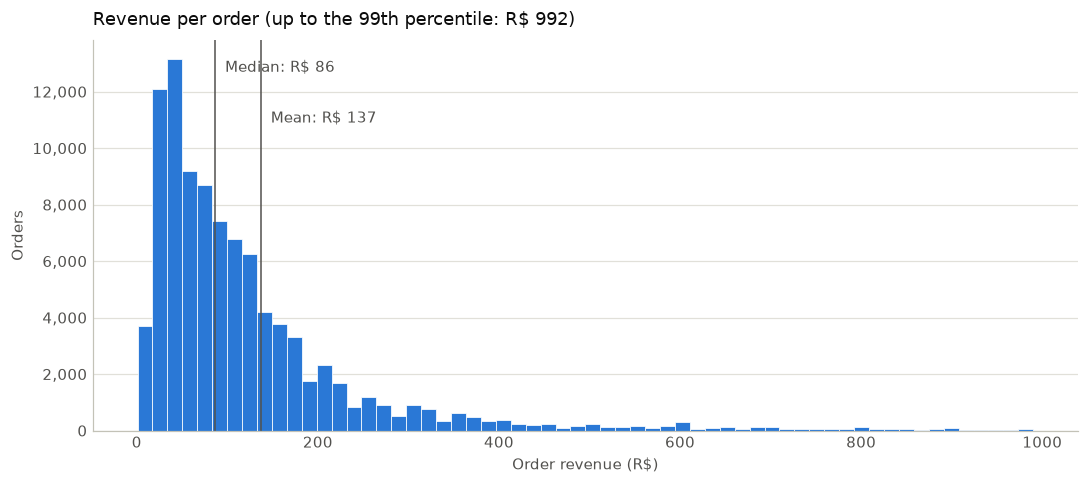

Freight represents 14.3% of what customers pay


In [14]:
mean = order_values["revenue"].mean()
median = order_values["revenue"].median()
limit = order_values["revenue"].quantile(0.99)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(order_values.loc[order_values["revenue"] <= limit, "revenue"], bins=60, color=BLUE,
             edgecolor="white", linewidth=0.5, alpha=1, ax=ax)
height = ax.get_ylim()[1]
for value, name, position in [(median, "Median", 0.95), (mean, "Mean", 0.82)]:
    ax.axvline(value, color=SECONDARY_INK, linewidth=1)
    ax.text(value, height * position, f"  {name}: R$ {value:.0f}", color=SECONDARY_INK, va="top")

ax.set_title(f"Revenue per order (up to the 99th percentile: R$ {limit:,.0f})")
ax.set_xlabel("Order revenue (R$)")
ax.set_ylabel("Orders")
ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

freight_share = order_values["freight_value"].sum() / order_values["total_value"].sum()
print(f"Freight represents {freight_share:.1%} of what customers pay")

The average ticket is R$ 137, but half of the orders do not exceed R$ 86.50 (the median). The mean sits above the median because a few very expensive orders pull it up: the most expensive 1% of orders exceed R$ 991.86, and the largest order reached R$ 13,440. That is why the median describes a typical order better than the mean.

Including freight, customers pay R$ 159.78 per order on average, and freight represents 14.3% of what they pay.

## 7. Products per purchase

In [15]:
units = order_values["units"].clip(upper=5).value_counts().sort_index()
units.index = ["1", "2", "3", "4", "5 or more"]
units_share = (units / units.sum() * 100).round(2)

print(f"Average units per order: {order_values['units'].mean():.2f}")
units_share.to_frame("% of orders")

Average units per order: 1.14


,% of orders
1,90.02
2,7.66
3,1.35
4,0.51
5 or more,0.46


In [16]:
single_product = run_sql("single_product_orders", **PERIOD)
single_product.round(1)

-- Share of orders that contain a single distinct product
SELECT
    100.0 * AVG(distinct_products = 1) AS single_product_pct
FROM (
    SELECT
        order_id,
        COUNT(DISTINCT product_id) AS distinct_products
    FROM items
    WHERE purchase_date >= :start
      AND purchase_date < :end
    GROUP BY order_id
);



,single_product_pct
0,96.7


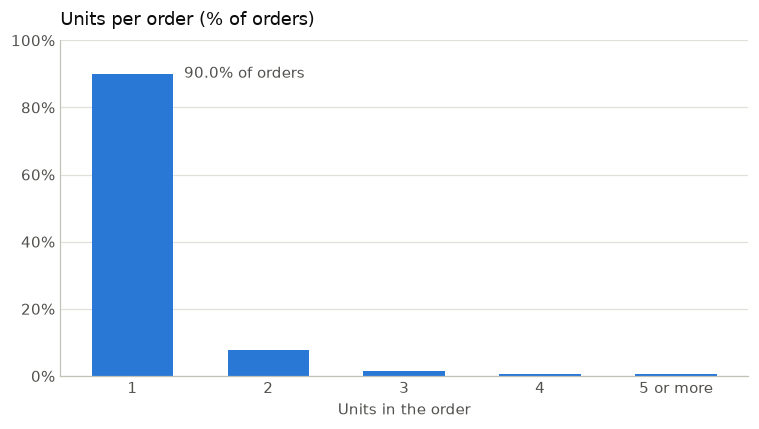

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(units_share.index, units_share.to_numpy(), color=BLUE, width=0.6)

# Only the bar that tells the story gets a label: single-unit orders
first = bars[0]
ax.text(first.get_x() + first.get_width() + 0.08, first.get_height(),
        f"{units_share.iloc[0]:.1f}% of orders", ha="left", va="center", color=SECONDARY_INK)
ax.set_title("Units per order (% of orders)")
ax.set_xlabel("Units in the order")
ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0f}%")
ax.set_ylim(0, 100)
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

90.0% of orders contain a single unit and 96.7% contain a single distinct product. On average, each order has 1.14 units. Olist customers buy one product at a time, so selling more depends on getting more orders rather than on making each purchase bigger.

When this analysis is run on the agricultural machinery business data, this indicator will show whether customers buy single machines or combine machines with spare parts.

## 8. Sales by category

This is a first look at categories. The detailed ranking, the Pareto analysis and the ABC classification are the subject of Phase 3. The query uses window functions to compute each category's share of revenue, its cumulative share and its rank by revenue and by units in a single pass.

In [18]:
categories = run_sql("category_ranking", **PERIOD).set_index("category")
print(f"Categories with sales in the period: {len(categories)}")
print(f"Revenue share of the top 10: {categories['revenue_pct'].head(10).sum():.1f}%")
categories.head(15).round(1)

-- Categories ranked by revenue and by units, with each category's share and cumulative share of revenue
WITH category_sales AS (
    SELECT
        category,
        SUM(price) AS revenue,
        COUNT(*) AS units,
        COUNT(DISTINCT product_id) AS products,
        AVG(price) AS avg_price
    FROM items
    WHERE purchase_date >= :start
      AND purchase_date < :end
    GROUP BY category
)
SELECT
    category,
    revenue,
    units,
    products,
    avg_price,
    100.0 * revenue / SUM(revenue) OVER () AS revenue_pct,
    100.0 * SUM(revenue) OVER (ORDER BY revenue DESC ROWS UNBOUNDED PRECEDING)
        / SUM(revenue) OVER () AS cumulative_pct,
    RANK() OVER (ORDER BY revenue DESC) AS rank_by_revenue,
    RANK() OVER (ORDER BY units DESC) AS rank_by_units
FROM category_sales
ORDER BY revenue DESC;



Categories with sales in the period: 74
Revenue share of the top 10: 62.5%


,revenue,units,products,avg_price,revenue_pct,cumulative_pct,rank_by_revenue,rank_by_units
category,,,,,,,,
Health beauty,1229557.5,9422,2380,130.5,9.3,9.3,1,2
Watches gifts,1163187.9,5853,1297,198.7,8.8,18.2,2,7
Bed bath table,1022955.8,10945,2987,93.5,7.8,25.9,3,1
Sports leisure,952661.4,8413,2811,113.2,7.2,33.1,4,3
Computers accessories,887944.6,7631,1597,116.4,6.7,39.9,5,5
Furniture decor,706237.2,8095,2559,87.2,5.4,45.2,6,4
Housewares,614341.6,6783,2281,90.6,4.7,49.9,7,6
Cool stuff,609158.0,3711,767,164.1,4.6,54.5,8,12
Auto,577721.1,4131,1847,139.9,4.4,58.9,9,10


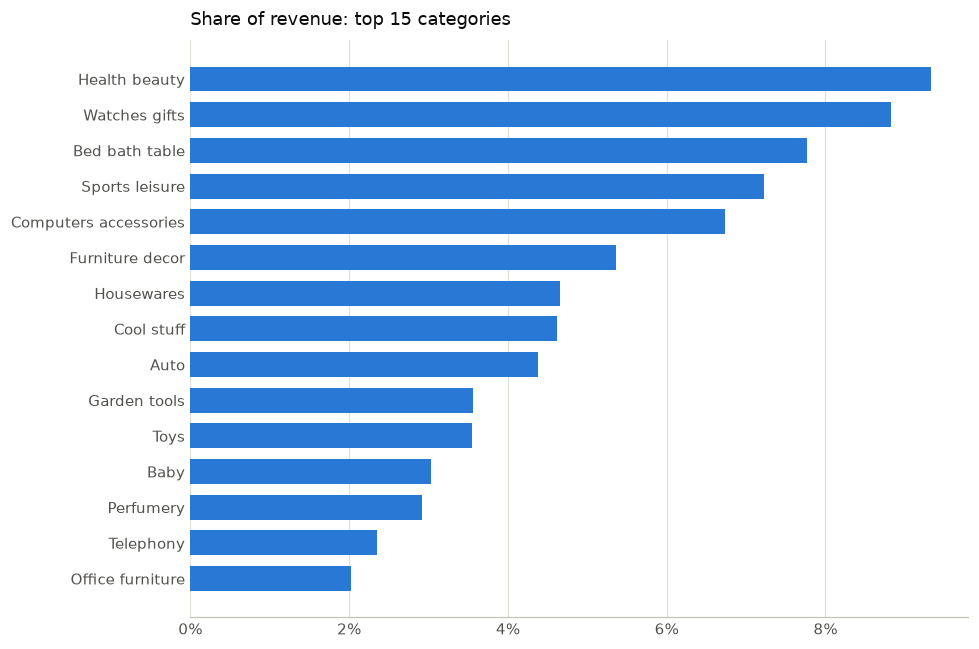

In [19]:
top = categories.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top["revenue_pct"].to_numpy(), color=BLUE, height=0.7)
ax.set_title("Share of revenue: top 15 categories")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:.0f}%")
ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
fig.tight_layout()
plt.show()

The category closest to the agricultural machinery business is "Agro industry and commerce". It is worth looking at it separately:

In [20]:
categories.loc[["Agro industry and commerce"]].round(1)

,revenue,units,products,avg_price,revenue_pct,cumulative_pct,rank_by_revenue,rank_by_units
category,,,,,,,,
Agro industry and commerce,70566.1,206,71,342.6,0.5,93.5,30,45


No category exceeds 10% of revenue, but the top 10 (14% of the 74 categories) add up to 62.5%. Health beauty brings in the most revenue (9.3%).

The ranking changes depending on whether we measure revenue or units. Bed bath table sells the most units but ranks third in revenue because its average price is low (R$ 93.50). Watches gifts does the opposite: seventh in units and second in revenue, with an average price of R$ 198.70. This difference is the starting point of Phase 3: a product can sell a lot and bring in little money, or the other way around.

Agro industry and commerce, the category closest to the agricultural machinery business, has a very different profile: it sold only 206 units (45th out of 74), but its average price, R$ 342.60, is far higher than that of any of the top 15 categories. Few sales of high value is the same pattern we expect in machinery sales.

## 9. Sales by region

Brazil has 27 states grouped into five regions. We first create a SQL view that adds the region to every order with a `CASE` expression, so the next queries can group by region directly.

In [21]:
run_sql_script("orders_with_region_view")

-- View that adds the Brazilian region of the customer's state to every order
DROP VIEW IF EXISTS orders_with_region;

CREATE VIEW orders_with_region AS
SELECT
    *,
    CASE
        WHEN customer_state IN ('AC', 'AP', 'AM', 'PA', 'RO', 'RR', 'TO') THEN 'North'
        WHEN customer_state IN ('AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE') THEN 'Northeast'
        WHEN customer_state IN ('DF', 'GO', 'MT', 'MS') THEN 'Central-West'
        WHEN customer_state IN ('ES', 'MG', 'RJ', 'SP') THEN 'Southeast'
        WHEN customer_state IN ('PR', 'RS', 'SC') THEN 'South'
    END AS region
FROM orders;



For each region we compute revenue, average ticket, average freight, median delivery days and the share of orders delivered late. SQLite has no median function, so the query computes it with window functions. The city-level analysis, with maps, is the subject of Phase 5.

In [22]:
regions = run_sql("sales_by_region", **PERIOD).set_index("region")
regions.round(1)

-- Sales, average ticket, freight, delivery time and late deliveries by region.
-- SQLite has no MEDIAN function, so the median delivery time is computed with window functions:
-- we number each region's orders by delivery time and average the one or two middle positions.
WITH period_orders AS (
    SELECT *
    FROM orders_with_region
    WHERE purchase_date >= :start
      AND purchase_date < :end
),
ranked AS (
    SELECT
        region,
        delivery_days,
        ROW_NUMBER() OVER (PARTITION BY region ORDER BY delivery_days) AS position,
        COUNT(*) OVER (PARTITION BY region) AS region_orders
    FROM period_orders
),
medians AS (
    SELECT
        region,
        AVG(delivery_days) AS median_delivery_days
    FROM ranked
    WHERE position IN ((region_orders + 1) / 2, (region_orders + 2) / 2)
    GROUP BY region
)
SELECT
    p.region,
    COUNT(*) AS orders,
    SUM(p.revenue) AS revenue,
    AVG(p.revenue) AS avg_ticket,
    AVG(p.freight_value) AS avg_freight,
    m.me

,orders,revenue,avg_ticket,avg_freight,median_delivery_days,late_pct,revenue_pct
region,,,,,,,
Southeast,66020,8621941.3,130.6,19.8,9.0,6.1,65.4
South,13767,1895017.0,137.6,24.3,12.0,5.9,14.4
Northeast,9015,1491911.3,165.5,36.0,17.0,12.8,11.3
Central-West,5610,844960.6,150.6,26.5,13.0,6.5,6.4
North,1791,325947.6,182.0,41.3,20.0,8.6,2.5


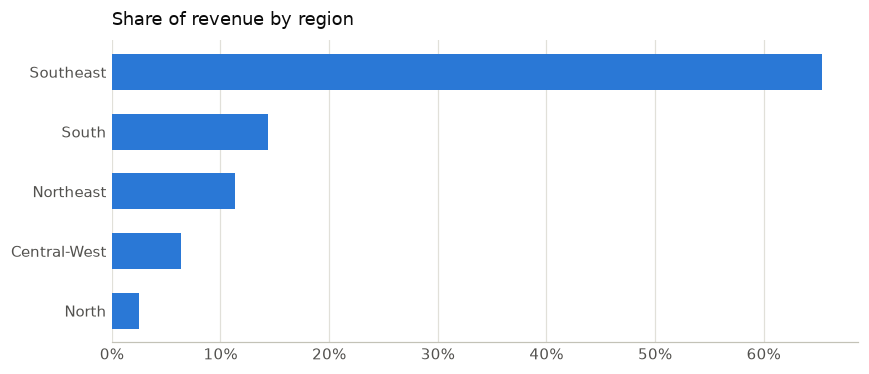

In [23]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ordered = regions.iloc[::-1]
ax.barh(ordered.index, ordered["revenue_pct"].to_numpy(), color=BLUE, height=0.6)
ax.set_title("Share of revenue by region")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:.0f}%")
ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
fig.tight_layout()
plt.show()

In [24]:
run_sql("sales_by_state", **PERIOD).head(10).round(1)

-- Orders, revenue, average ticket and share of revenue by customer state
SELECT
    customer_state,
    region,
    COUNT(*) AS orders,
    SUM(revenue) AS revenue,
    AVG(revenue) AS avg_ticket,
    100.0 * SUM(revenue) / SUM(SUM(revenue)) OVER () AS revenue_pct
FROM orders_with_region
WHERE purchase_date >= :start
  AND purchase_date < :end
GROUP BY customer_state, region
ORDER BY revenue DESC;



,customer_state,region,orders,revenue,avg_ticket,revenue_pct
0,SP,Southeast,40399,5054517.0,125.1,38.4
1,RJ,Southeast,12310,1751433.8,142.3,13.3
2,MG,Southeast,11319,1548206.9,136.8,11.7
3,RS,South,5327,726194.9,136.3,5.5
4,PR,South,4903,664048.0,135.4,5.0
5,SC,South,3537,504774.1,142.7,3.8
6,BA,Northeast,3253,493339.3,151.7,3.7
7,DF,Central-West,2074,295454.6,142.5,2.2
8,GO,Central-West,1950,281932.2,144.6,2.1
9,ES,Southeast,1992,267783.7,134.4,2.0


Where the sellers are helps explain freight costs and delivery times by region:

In [25]:
run_sql("seller_location", **PERIOD).round(1)

-- Share of sellers located in São Paulo and in the Southeast, among sellers with sales in the period
WITH sellers AS (
    SELECT DISTINCT
        seller_id,
        seller_state
    FROM items
    WHERE purchase_date >= :start
      AND purchase_date < :end
)
SELECT
    COUNT(*) AS sellers,
    100.0 * AVG(seller_state = 'SP') AS sellers_in_sao_paulo_pct,
    100.0 * AVG(seller_state IN ('ES', 'MG', 'RJ', 'SP')) AS sellers_in_southeast_pct
FROM sellers;



,sellers,sellers_in_sao_paulo_pct,sellers_in_southeast_pct
0,2945,59.5,73.7


The Southeast accounts for 65.4% of revenue, and the state of São Paulo alone contributes 38.4%. It is also where most sellers are located: 59.5% of them are in São Paulo and 73.7% in the Southeast.

The table shows a relationship we will come back to in Phase 5: the farther from the Southeast, the more expensive and slower the delivery. In the North, freight costs R$ 41.30 on average and the median delivery takes 20 days, compared with R$ 19.80 and 9 days in the Southeast. The Northeast has the highest share of late deliveries (12.8%, twice the Southeast's 6.1%).

Customers in the more distant regions also spend more per order: R$ 182 in the North versus R$ 131 in the Southeast. One possible explanation, which we will check in Phase 5, is that expensive shipping makes cheap products less attractive, so these customers mostly buy higher-value items.

For the machinery business this becomes a concrete question: how much does it cost, and how long does it take, to serve customers in distant areas? It is one of the criteria for deciding where to open a new branch.

## 10. Payment methods

In [26]:
run_sql("payment_mix", **PERIOD).round(1)

-- Share of orders by main payment method
SELECT
    payment_type,
    COUNT(*) AS orders,
    100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS orders_pct
FROM orders
WHERE purchase_date >= :start
  AND purchase_date < :end
  AND payment_type IS NOT NULL
GROUP BY payment_type
ORDER BY orders DESC;



,payment_type,orders,orders_pct
0,Credit card,72612,75.5
1,Boleto,19140,19.9
2,Voucher,2970,3.1
3,Debit card,1481,1.5


Three out of four orders are paid by credit card (75.5%) and one in five with a boleto (19.9%). Credit cards allow paying in installments; in Phase 6 we will check whether the payment method is related to customers coming back.

## 11. Saving

We save the monthly table for the dashboard. The `month` column holds the first day of each month, a date format Power BI recognizes directly, and `is_complete_month` flags August 2018 so it is not read as a normal month.

In [27]:
monthly_sales = (
    monthly.round({"revenue": 2, "avg_ticket": 2, "orders_per_day": 2})
    .reset_index()
    .assign(month=lambda df: df["month"].dt.to_timestamp())
)
monthly_sales.to_csv(PROCESSED / "monthly_sales.csv", index=False)
print(f"monthly_sales.csv: {len(monthly_sales)} rows")
monthly_sales.head(3)

monthly_sales.csv: 20 rows


,month,orders,units,revenue,avg_ticket,customers,orders_per_day,is_complete_month
0,2017-01-01,750,913,111798.36,149.06,718,24.19,True
1,2017-02-01,1653,1858,234223.40,141.70,1630,59.04,True
2,2017-03-01,2546,2897,359198.85,141.08,2508,82.13,True


## Key insights

- The business grew strongly during 2017 and stabilized in 2018 at 6,100 to 7,100 orders per month. Between January and July, orders grew 160.8% year over year.
- Growth came from the number of orders: the average ticket stayed between R$ 124 and R$ 149 throughout the period. The typical order (median) is R$ 86.50 and contains a single unit.
- The high season is November, driven by Black Friday. 2018 shows a dip in June and July and a strong recovery in August, but with less than two years of data we cannot confirm that these patterns repeat.
- Customers buy more from Monday to Friday, especially on Mondays, and between 10:00 and 23:00. Weekend sales are 25% lower.
- Sales are spread across many categories, and the ranking changes depending on whether it is measured by units or by revenue. That difference is the starting point of Phase 3.
- The Southeast concentrates 65% of revenue. Distant regions pay more for freight and wait longer, a central topic for Phase 5.
- August 2018 is incomplete. In `monthly_sales.csv`, the `is_complete_month` column flags it so it is not treated as a normal month in the forecast or the dashboard.